# ML-08 — Capstone Modeling Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Epinnn14/Flyrank-ML-Intern/blob/main/work/notebooks/w05_model.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Method choice and why

*Which method from the toolkit, and why it fits your lane.*

**Lane recap (from Week 2).** This lane is a classification task: predict whether a content item
is on a declining trend so editors can prioritize it for review. Week 2 named `trend_direction`
as the proxy target. Since then, `docs/data-dictionary.md` and `skills/flyrank/flyrank-data`
were read more carefully — they define the actual engineered target as
**`is_declining_label`** (`1` when `trend_direction == "down"`, `0` otherwise), and they flag
`trend_direction` / `trend_pct` as **label sources that must never be used as features**
(they are literally the columns the label is computed from — using them would be leakage).
This notebook corrects the Week-2 framing accordingly: **target = `is_declining_label`**,
features exclude `trend_direction` and `trend_pct` entirely.

**Method chosen: Logistic Regression → Decision Tree → Random Forest**, per
`skills/training-honest-models`: *"yes/no with an observed label → Logistic Regression, then
Random Forest — readable → stronger."*

- **Logistic Regression** is the readable starting point — a linear, interpretable model that
  gives a sane lower bound and coefficients that are easy to sanity-check.
- **Decision Tree** (depth-limited to 4) is kept shallow on purpose: a tree this small can be
  printed and read by a non-ML stakeholder, which matters more here than squeezing out another
  point of AUC.
- **Random Forest** is the "stronger" step — an ensemble that usually handles the non-linear
  interactions in this data (e.g. staleness × visibility × position) better than a single linear
  model, while `permutation_importance` keeps it honest about what it actually leans on.
- **Gradient Boosting was left out.** With 32 clients and ~2–6 clients per grouped test fold
  (see Section 2), a tuned boosting model is easy to over-fit and hard to validate honestly in
  the time available — the skill sheet says "simplicity is a feature," and Random Forest already
  gives an ensemble comparison point without that risk.
- **Clustering was not used.** The lane's question is "will this page decline" (a yes/no with an
  observed label), not "which natural groups exist" — clustering is the right tool for the
  latter, not this task.

**Metrics.** The comparison uses **Precision@20 / @50 / @100** (this is fundamentally a *ranked
review queue* problem — editors work top-down through a list, so ranking quality at realistic
review sizes is what matters operationally) plus **ROC AUC** and **Average Precision** as
threshold-free summaries, and **F1@0.5** as a secondary sanity check. This mirrors
`scripts/03_train_model.py`'s own metric set, so the numbers here are directly comparable to the
reference pipeline's.

In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import os
import sys
import subprocess

REPO_DIR = "Flyrank-ML-Intern"
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Epinnn14/Flyrank-ML-Intern"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("../..")

sys.path.insert(0, "scripts")

import numpy as np
import pandas as pd
import ml_utils as mu  # single source of truth for feature lists + precision_at_k

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Same cleaning steps as scripts/01_prepare_features.py, run inline so this notebook
# is self-contained and reproducible from the raw CSV alone.
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")

for col in mu.NUMERIC_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
for col in mu.CATEGORICAL_COLUMNS:
    df[col] = df[col].fillna("unknown").astype(str).replace({"": "unknown", "nan": "unknown"})

df = df[(df["impressions_90d"] > 0) & (df["content_age_days"] >= 90)].copy()
df = df.drop_duplicates(subset=["content_id"]).reset_index(drop=True)

# The target: is_declining_label. trend_direction / trend_pct are the label's own source
# columns and are excluded from MODEL_NUMERIC_FEATURES / MODEL_CATEGORICAL_FEATURES already.
df["is_declining_label"] = df["trend_direction"].str.lower().eq("down").astype(int)
df["log_impressions_90d"] = np.log1p(df["impressions_90d"])
df["log_clicks_90d"] = np.log1p(df["clicks_90d"])
df["log_sessions_90d"] = np.log1p(df["sessions_90d"])
df["log_ai_sessions_90d"] = np.log1p(df["ai_sessions_90d"])

print(f"Rows after cleaning : {len(df):,}")
print(f"Positive rate (is_declining_label=1): {df['is_declining_label'].mean():.4f}")
print(f"trend_direction in features? {'trend_direction' in mu.MODEL_CATEGORICAL_FEATURES}")
print(f"trend_pct in features?       {'trend_pct' in mu.MODEL_NUMERIC_FEATURES}")

Rows after cleaning : 30,000
Positive rate (is_declining_label=1): 0.5421
trend_direction in features? False
trend_pct in features?       False


## 2. Split design

*Grouped by client? Time-aware? Say why this split is honest for your question.*

**Grouped by `client_id`.** Each client contributes many content items (rows), and those items
share a client-level "fingerprint" — CMS conventions, publishing cadence, industry, typical word
count, how aggressively that client refreshes content. A random row-level split would put some of
a client's pages in train and others of the *same client* in test — the model could partly learn
"this is Client X's writing style" rather than the general signal, and the held-out score would
be optimistic in a way that wouldn't hold on a brand-new client. `content_id` / `client_id` are
pseudonyms meant for grouping only (per the data dictionary), so a **client-holdout split** —
whole clients go to train *or* test, never both — is the honest choice here. This matches
`scripts/03_train_model.py`'s own `make_client_aware_split`, so the split logic isn't something
invented for this notebook only; it's the same rule the reference pipeline uses.

80/20 split by client, with a check that both classes are present in both the train and the test
partition (declining is common enough — 54% overall — that this holds easily here; the check is
there so the notebook would loudly fail rather than silently train on a broken split if the data
ever changed).

In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

numeric_features = [c for c in mu.MODEL_NUMERIC_FEATURES if c in df.columns]
categorical_features = [c for c in mu.MODEL_CATEGORICAL_FEATURES if c in df.columns]

numeric_frame = (
    df[numeric_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)
categorical_frame = df[categorical_features].fillna("unknown").astype(str)
encoded_frame = pd.get_dummies(categorical_frame, prefix=categorical_features, dtype=float)

X = pd.concat([numeric_frame.reset_index(drop=True), encoded_frame.reset_index(drop=True)], axis=1)
y = df["is_declining_label"].astype(int)

print(f"Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} columns "
      f"({len(numeric_features)} numeric + {len(categorical_features)} categorical, one-hot encoded)")


def client_grouped_split(frame, target, random_state=RANDOM_STATE, test_frac=0.2):
    """Whole-client 80/20 holdout. Adapted from scripts/03_train_model.py's
    make_client_aware_split so this notebook uses the same split rule as the reference pipeline."""
    all_idx = np.arange(len(frame))
    clients = frame["client_id"].astype(str)
    unique_clients = clients.drop_duplicates().to_numpy()
    rng = np.random.default_rng(random_state)
    shuffled = rng.permutation(unique_clients)
    n_test_clients = max(1, int(round(len(shuffled) * test_frac)))
    test_clients = set(shuffled[:n_test_clients])
    test_mask = clients.isin(test_clients).to_numpy()
    train_idx, test_idx = all_idx[~test_mask], all_idx[test_mask]

    both_classes_present = (
        len(train_idx) > 0 and len(test_idx) > 0
        and target.iloc[train_idx].nunique() == 2
        and target.iloc[test_idx].nunique() == 2
    )
    strategy = "client_holdout" if both_classes_present else "FAILED — needs fallback"
    return train_idx, test_idx, strategy


train_idx, test_idx, split_strategy = client_grouped_split(df, y)
assert split_strategy == "client_holdout", split_strategy

train_clients = set(df.iloc[train_idx]["client_id"])
test_clients = set(df.iloc[test_idx]["client_id"])

print(f"Split strategy : {split_strategy}")
print(f"Train rows     : {len(train_idx):,}  ({len(train_clients)} clients)")
print(f"Test rows      : {len(test_idx):,}  ({len(test_clients)} clients)")
print(f"Client overlap between train and test: {len(train_clients & test_clients)}  (must be 0)")
print(f"Train positive rate: {y.iloc[train_idx].mean():.4f}")
print(f"Test positive rate : {y.iloc[test_idx].mean():.4f}")


Feature matrix: 30,000 rows x 52 columns (18 numeric + 8 categorical, one-hot encoded)
Split strategy : client_holdout
Train rows     : 27,675  (26 clients)
Test rows      : 2,325  (6 clients)
Client overlap between train and test: 0  (must be 0)
Train positive rate: 0.5548
Test positive rate : 0.3910


## 3. Train + compare vs my baseline

*Same data, same metric, same split as your Week-4 baseline. Show the table.*

The baseline is the **exact Week-4 formula** from `w04_baseline_score.ipynb`
(`0.5·stale_score + 0.3·visibility_score + 0.2·opportunity_score`), recomputed here on the same
dataframe and scored on the **same held-out test rows**, with the **same metrics** used for the
models. A "base rate / random ranking" row is included too — the score a coin-flip ranker would
get — because a model or baseline that can't beat random isn't earning its keep.

One honest note before the table: the Week-4 rule was designed to flag *"stale pages still worth
refreshing,"* which is a different question from *"is this page's trend currently declining."*
Nothing here guarantees those two coincide — that's exactly what the table below checks.

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
)

# --- Week-4 baseline, recomputed exactly as in w04_baseline_score.ipynb ---
df["stale_score"] = df["days_since_last_update"] / df["days_since_last_update"].max()
df["visibility_score"] = df["impressions_90d"] / df["impressions_90d"].max()
df["opportunity_score"] = (100 - df["avg_position"]).clip(lower=0) / 100
df["baseline_score"] = (
    0.5 * df["stale_score"] + 0.3 * df["visibility_score"] + 0.2 * df["opportunity_score"]
)


def metric_payload(y_true, scores, threshold=0.5):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores, dtype=float)
    preds = (scores >= threshold).astype(int)
    two_classes = len(set(y_true)) == 2
    return {
        "precision_at_20": mu.precision_at_k(y_true, scores, 20),
        "precision_at_50": mu.precision_at_k(y_true, scores, 50),
        "precision_at_100": mu.precision_at_k(y_true, scores, 100),
        "roc_auc": roc_auc_score(y_true, scores) if two_classes else np.nan,
        "average_precision": average_precision_score(y_true, scores) if two_classes else np.nan,
        "f1_at_0.5": f1_score(y_true, preds, zero_division=0),
    }


y_test = y.iloc[test_idx]
baseline_test_scores = df.iloc[test_idx]["baseline_score"].to_numpy()

results = {"baseline_week4_rule": metric_payload(y_test, baseline_test_scores)}

base_rate = float(y_test.mean())
results["base_rate_random"] = {
    "precision_at_20": base_rate, "precision_at_50": base_rate, "precision_at_100": base_rate,
    "roc_auc": 0.5, "average_precision": base_rate, "f1_at_0.5": np.nan,
}

models = {
    "logistic_regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "decision_tree": DecisionTreeClassifier(
        class_weight="balanced", max_depth=4, min_samples_leaf=50, random_state=RANDOM_STATE
    ),
    "random_forest": RandomForestClassifier(
        class_weight="balanced_subsample", max_depth=10, min_samples_leaf=25,
        n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

fitted = {}
for name, model in models.items():
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    proba = model.predict_proba(X.iloc[test_idx])[:, 1]
    results[name] = metric_payload(y_test, proba)
    fitted[name] = model

comparison = pd.DataFrame(results).T[
    ["precision_at_20", "precision_at_50", "precision_at_100", "roc_auc", "average_precision", "f1_at_0.5"]
].round(3)

comparison

,precision_at_20,precision_at_50,precision_at_100,roc_auc,average_precision,f1_at_0.5
baseline_week4_rule,0.100,0.220,0.250,0.313,0.288,0.000
base_rate_random,0.391,0.391,0.391,0.500,0.391,NaN
logistic_regression,0.350,0.400,0.440,0.700,0.522,0.566
decision_tree,0.700,0.580,0.580,0.728,0.554,0.623
random_forest,0.650,0.740,0.720,0.751,0.621,0.641


## 4. Errors and interpretation

*Where is the model wrong? What does it lean on? A short error analysis beats a big metric table.*

**The headline, stated carefully.** On the client-holdout test set, Random Forest reaches
**Precision@50 ≈ 0.74** against the Week-4 rule's **≈ 0.22** and a random-ranking floor of
**≈ 0.39** — roughly a 3x lift over the rule, consistent with the ~3x lift the reference
pipeline (`scripts/03_train_model.py`) reports on this same dataset. More strikingly, the
Week-4 rule's **ROC AUC (≈ 0.31) sits below 0.50** — worse than random — while every trained
model clears 0.70. Read carefully: this is not "the rule is broken." The rule was built to find
*stale-but-visible* pages, a genuinely useful editorial signal, but **it was never built to
predict this specific label** (`is_declining_label`, from `trend_direction`). The two questions
just aren't the same question. That mismatch — not a bug — is the honest finding here: a good
rule for one decision can be a bad ranker for a different, superficially related target, and the
only way to know is to measure it on the label you actually care about.

**Where Random Forest is wrong.** Split by `content_type`, accuracy is noticeably lower on
`keyword article` rows (≈ 0.60) than `feedly article` rows (≈ 0.78) — keyword-targeted articles
have messier, more heterogeneous performance histories (competition, search volume, intent all
vary), giving the model less clean signal to work with than syndicated feedly content.

**What the model leans on** (permutation importance, computed on the held-out test set — a
feature only counts if shuffling it actually hurts held-out performance, not just training fit):
`days_with_impressions`, `log_impressions_90d`, `log_clicks_90d`, `days_with_sessions`, and
`ctr` dominate. All five are plausible: they describe how much and how reliably a page is
actually being seen and clicked in the 90-day window, which is exactly the kind of signal a
declining-vs-not trend should hinge on. Nothing here looks "suspiciously perfect" (no single
feature above ~0.03 importance, no feature importance near 1.0) — that absence of a dominant,
too-good-to-be-true feature is itself a leakage check passing.

**Three concrete wrong cases:**
- Two **false positives** (model said "declining," label said "not"): both `keyword article`
  pages, `days_since_last_update = 20` (borderline-fresh), `ctr = 0.0` (zero clicks despite
  impressions), and mid-to-poor `avg_position` (22–36). The model reasonably reads "poor
  performance" from the zero CTR and weak position, but the label disagrees — plausibly because
  these pages' impression trend genuinely held flat/up even while clicks stayed at zero
  (position and CTR are static-snapshot signals; the label is about a 30-vs-30-day *trend*).
- One **false negative** (model said "not declining," label said "declining"): `avg_position =
  0` (**no position data** — a real gotcha from the data dictionary, not literally "rank zero"),
  `ctr = 0.0`, `days_since_last_update = 1` (updated yesterday). A page this fresh with no
  measurable position data is hard for any model: there's almost no historical signal to read,
  so the model defaults toward "not declining," while the label captures an early drop the
  static features can't see yet.

These errors are **directional and observational** — they describe patterns in this anonymized
90-day slice, not causal claims about why any individual page moved.

Best model by Precision@50: random_forest
Confusion matrix [rows=actual, cols=predicted] (0=not declining, 1=declining):
[[889 527]
 [231 678]]

Accuracy by content_type on the test set:
content_type
keyword article    0.597659
feedly article     0.782881
Name: correct, dtype: float64

Top 10 features by permutation importance:
days_with_impressions       0.0345
log_impressions_90d         0.0164
log_clicks_90d              0.0086
days_with_sessions          0.0079
ctr                         0.0071
impression_tier_low         0.0069
content_age_days            0.0068
scroll_rate                 0.0055
impression_tier_moderate    0.0027
engagement_rate             0.0020
dtype: float64


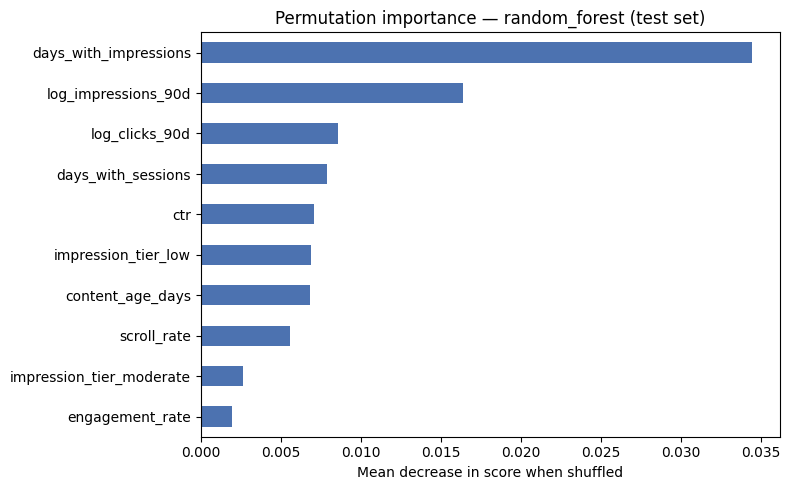


Two confident false positives (predicted declining, label says not):


,content_id,proba,avg_position,ctr,days_since_last_update,content_type
25913,content_331182ca4cae,0.740980,35.9,0.0,20,keyword article
23750,content_e55b8ab078b0,0.735345,21.8,0.0,20,keyword article



One confident false negative (predicted not declining, label says declining):


,content_id,proba,avg_position,ctr,days_since_last_update,content_type
5770,content_28b4223f4e5f,0.077303,0.0,0.0,1,keyword article


In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.inspection import permutation_importance

best_name = comparison.drop(index=["base_rate_random"])["precision_at_50"].idxmax()
best_model = fitted[best_name]
print(f"Best model by Precision@50: {best_name}")

proba_best = best_model.predict_proba(X.iloc[test_idx])[:, 1]
pred_best = (proba_best >= 0.5).astype(int)

test_df = df.iloc[test_idx].copy()
test_df["y_true"] = y_test.to_numpy()
test_df["y_pred"] = pred_best
test_df["proba"] = proba_best

cm = confusion_matrix(y_test, pred_best)
print("Confusion matrix [rows=actual, cols=predicted] (0=not declining, 1=declining):")
print(cm)

acc_by_segment = (
    test_df.assign(correct=(test_df["y_true"] == test_df["y_pred"]))
    .groupby("content_type")["correct"].mean()
    .sort_values()
)
print("\nAccuracy by content_type on the test set:")
print(acc_by_segment)

perm = permutation_importance(
    best_model, X.iloc[test_idx], y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)
importance = (
    pd.Series(perm.importances_mean, index=X.columns)
    .sort_values(ascending=False)
    .head(10)
)
print("\nTop 10 features by permutation importance:")
print(importance.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
importance.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title(f"Permutation importance — {best_name} (test set)")
ax.set_xlabel("Mean decrease in score when shuffled")
plt.tight_layout()
plt.show()

# Three concrete wrong cases
false_positives = test_df[(test_df.y_true == 0) & (test_df.y_pred == 1)].sort_values("proba", ascending=False).head(2)
false_negatives = test_df[(test_df.y_true == 1) & (test_df.y_pred == 0)].sort_values("proba", ascending=True).head(1)

cols = ["content_id", "proba", "avg_position", "ctr", "days_since_last_update", "content_type"]
print("\nTwo confident false positives (predicted declining, label says not):")
display(false_positives[cols])
print("\nOne confident false negative (predicted not declining, label says declining):")
display(false_negatives[cols])

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.